# Chicago Crime 2022: Exploration, Hotspots and Forecasting

Every crime the Chicago Police Department recorded in 2022: almost 240,000 incidents, each with a type, a place to the city block, a time to
the minute, and whether anyone was arrested. This notebook cleans the records, asks **what** happens, **when** and **where**, finds the
hotspots on the map, and then builds forecasts of how many crimes each police district will see tomorrow — always against simple
baselines that a model must beat.

**Objectives**
1. Which problems hide in police records, and how should each be handled?
2. Which crimes dominate, and how concentrated are they?
3. When does crime happen — hour, weekday, month — and does the pattern differ by type?
4. Where does crime happen, and where are the hotspots?
5. Which incidents end in an arrest, and which are domestic?
6. How well can daily crime counts per district be forecast, and does a model beat "same as last week"?

**Data** → [Kaggle dataset "Crime Prediction in Chicago 2022"](https://www.kaggle.com/search?q=crime+prediction+in+chicago+2022) · 239,558 incidents · 1 Jan – 31 Dec 2022 ·
originally from the [Chicago Data Portal](https://data.cityofchicago.org/)

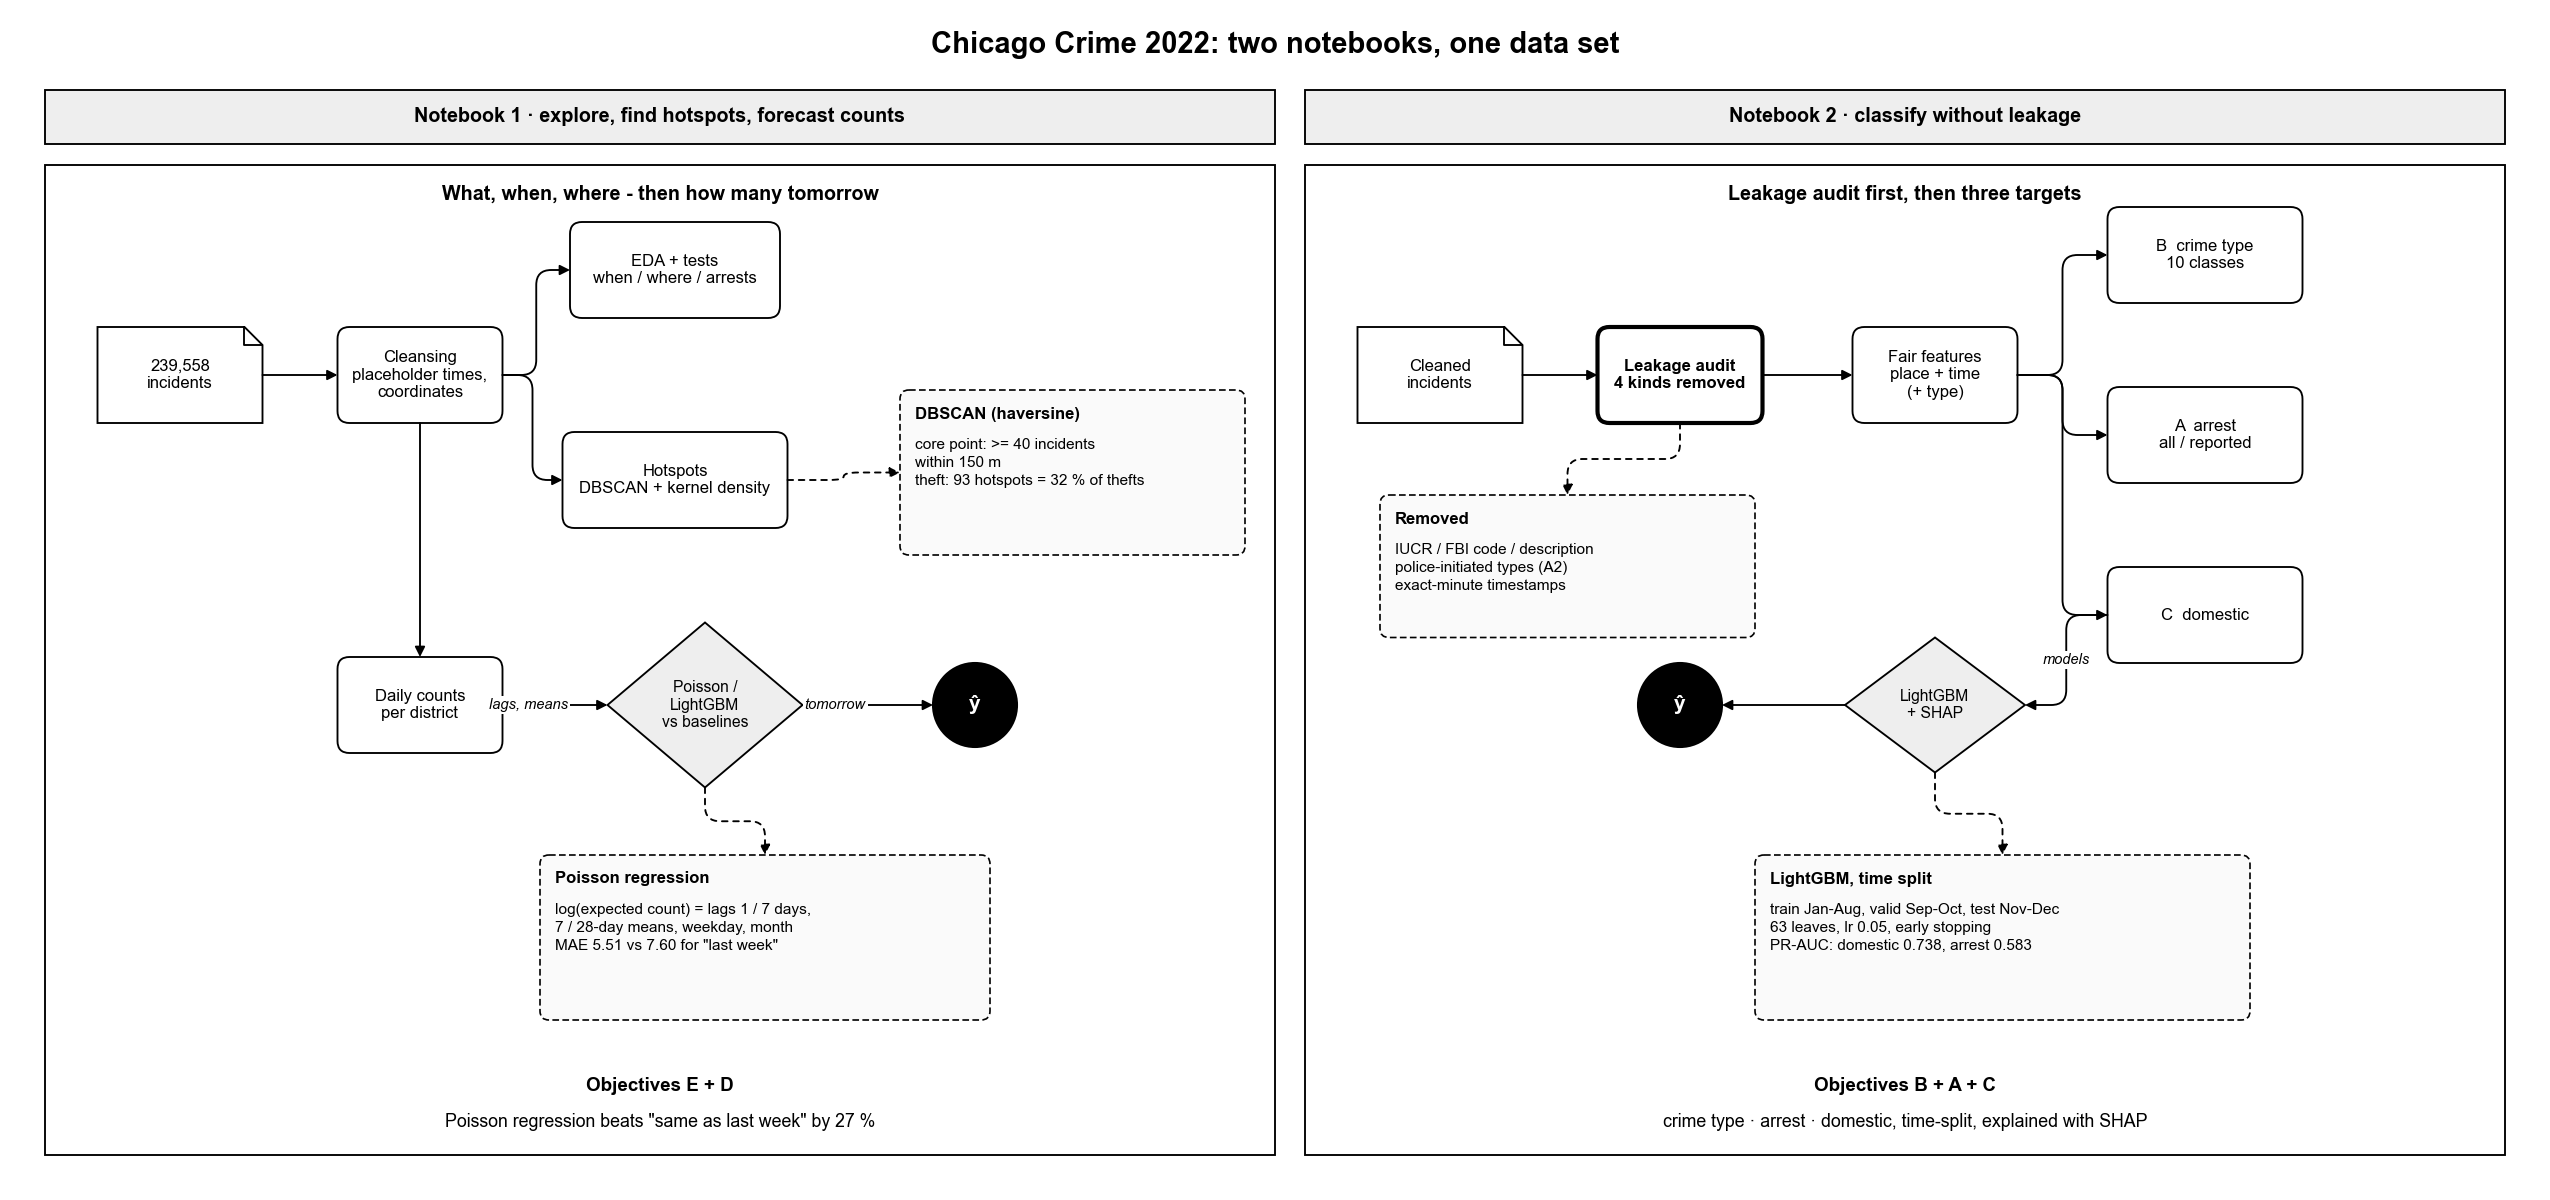

<!-- objective -->
## Objective

- **Problem** → a city has limited patrols, detectives and victim-support staff; it needs to know *what* happens *when* and *where*, how busy tomorrow will be, and which new reports need attention first
- **Why this repo** → clean the hidden recording artefacts, map the patterns, forecast daily counts per district, and classify new reports using only what is known when the report is filed
- **Real-world use** → patrol planning around theft hotspots, staffing from the daily forecast, and early flags for likely domestic cases so victim support can call sooner (never replacing the officer)

# [1/14] Setup

Set every knob once in the top cell → later cells only read them, and nothing is written unless `SAVE_FIGURES = True`

In [ ]:
"""Optional · Edit the settings, then run all cells. Explanations: README.md

[1/8] DATA_DIR: dataset folder (searched recursively under /kaggle/input for the crime CSV if not found here)
    Default = '/kaggle/input'
[2/8] WORK_DIR: folder for exported figures
    Default = '/kaggle/working'
[3/8] SEED: random seed
    Default = 42
[4/8] HOTSPOT_TYPES: crime types mapped and searched for hotspots
    Default = THEFT, BATTERY, MOTOR VEHICLE THEFT, ROBBERY
[5/8] DBSCAN_EPS_M / DBSCAN_MIN: hotspot radius in metres and minimum incidents per hotspot
    Default = 150 / 40
[6/8] TEST_START: first day of the forecasting test period
    Default = '2022-11-01'
[7/8] VALID_START: first day of the validation period (model tuning)
    Default = '2022-09-01'
[8/8] SAVE_FIGURES: write every chart to WORK_DIR/assets
    Default = False
"""
DATA_DIR      = '/kaggle/input'
WORK_DIR      = '/kaggle/working'
SEED          = 42
HOTSPOT_TYPES = ['THEFT', 'BATTERY', 'MOTOR VEHICLE THEFT', 'ROBBERY']
DBSCAN_EPS_M  = 150
DBSCAN_MIN    = 40
TEST_START    = '2022-11-01'
VALID_START   = '2022-09-01'
SAVE_FIGURES  = False

CHICAGO_BOX   = {'lat': (41.64, 42.03), 'lon': (-87.95, -87.52)}   # city limits, used to catch impossible coordinates
TOP_TYPES     = 10
EARTH_R_M     = 6_371_000
PAD           = 34
PALETTE       = {'main': 'black', 'flag': 'red', 'soft': 'grey'}
DAYS          = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats

import lightgbm as lgb
import statsmodels.api as sm
from sklearn.cluster import DBSCAN
from sklearn.metrics import mean_absolute_error
from sklearn.neighbors import KernelDensity

warnings.filterwarnings('ignore')
sns.set_style('darkgrid')
sns.set_palette('gray')
ASSETS = Path(WORK_DIR) / 'assets'
if SAVE_FIGURES:
    ASSETS.mkdir(parents=True, exist_ok=True)

In [ ]:
def show_block(title, items):
    print(f'{title}:')
    for key, value in items.items():
        print(f'    {key:<{PAD}}{value}')


def save(fig, name):
    if SAVE_FIGURES:
        fig.savefig(ASSETS / f'{name}.png', bbox_inches='tight', dpi=110)


def find_crime_csv(root):
    """First CSV under `root` (searched recursively) that has the Chicago crime columns."""
    import csv
    root = Path(root)
    candidates = [root] if root.is_file() else sorted(root.rglob('*.csv')) if root.exists() else []
    for f in candidates:
        with open(f, newline='', encoding='utf-8', errors='ignore') as fh:
            header = next(csv.reader(fh), [])
        if {'Primary Type', 'Arrest', 'Domestic', 'Beat'} <= set(header):
            return f
    raise FileNotFoundError(f'(!) No Chicago crime CSV under {root}.\n'
                            f'    Add Input -> Datasets -> search "Crime Prediction in Chicago 2022"')


def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(table)
    return chi2, p, np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))


def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    return float(((2 * np.arange(1, n + 1) - n - 1) * x).sum() / (n * x.sum()))

# [2/14] Data

Load the incident table → one row per recorded crime, 22 columns about what, where, when and the outcome

In [ ]:
csv_path = find_crime_csv(DATA_DIR)
raw = pd.read_csv(csv_path)
show_block('Inputs', {'file': csv_path.name, 'rows': f'{len(raw):,}', 'columns': raw.shape[1]})

In [ ]:
display(raw.head(3).T)

**Question:** What does each record tell us?

| Group | Columns | Use |
|---|---|---|
| What | `Primary Type` (31 types), `Description`, `IUCR` (Illinois crime code), `FBI Code` | target of the classification notebook; IUCR and description are *more detailed versions of the type* |
| Where | `Block` (address to the 100-block), `Beat` → `District`, `Ward`, `Community Area`, `Latitude`, `Longitude`, `Location Description` | maps, hotspots, grouping |
| When | `Date` (to the minute) | hour, weekday, month, daily counts |
| Outcome | `Arrest`, `Domestic` | rates and the classification notebook |
| Admin | `ID`, `Case Number`, `Updated On`, `Year`, `X/Y Coordinate`, `Location` | identifiers and duplicates of other columns |

**Answer:** 239,558 incidents × 22 columns; several repeat each other.
- `IUCR` and `Description` are finer versions of `Primary Type` (one IUCR code = one type)
- `X/Y Coordinate`, `Location` repeat latitude / longitude; `Year` is always 2022

# [3/14] Data cleansing

Check dates, duplicates, coordinates and gaps → fix or flag each problem and keep a log; no incident is deleted without a reason

**Question:** Which problems hide in police records, and how should each be handled?

- **Placeholder times** → when the exact time is unknown, records are often entered at **00:00** or on the **1st of the month**; those spikes are
  recording artefacts, not crime patterns
- **Rounded times** → officers often record the full hour (e.g. 15:00 instead of 15:07); exactly 12:00 and 00:01 are further placeholders for "some time that day"
- **Impossible coordinates** → points outside the city limits are data-entry errors
- **Duplicates** → a repeated case number may be an error, or several victims of one case: check before deleting
- Analogy → a diary where people write "midnight" whenever they forgot the time: the midnight entries are about memory, not about midnight

**Answer:** complete records, but the **times** lie; no row deleted.
- placeholders: 12,146 at 00:00, 6,455 at 12:00, 2,480 at 00:01; 1,714 extra on the 1st of a month
- 4,667 without coordinates (1.9 %) → maps only; 90 repeated case numbers = several homicide victims, kept
- → hour analysis uses the 149,236 precisely timed incidents (62.3 %)

In [ ]:
df = raw.copy()
log = []


def note(issue, rows, action):
    log.append({'issue': issue, 'rows': int(rows), 'action': action})


df['datetime'] = pd.to_datetime(df['Date'], format='%m/%d/%Y %H:%M', errors='coerce')
note('date not parseable', df['datetime'].isna().sum(), 'none found')
df['hour'] = df['datetime'].dt.hour
df['minute'] = df['datetime'].dt.minute
df['weekday'] = df['datetime'].dt.dayofweek
df['month'] = df['datetime'].dt.month
df['day'] = df['datetime'].dt.day
df['date'] = df['datetime'].dt.normalize()

midnight = (df['hour'] == 0) & (df['minute'] == 0)
note('time exactly 00:00 (placeholder)', midnight.sum(), 'kept; flagged time_unknown and excluded from hour-of-day analysis')
df['time_unknown'] = midnight
first_day_excess = (df['day'] == 1).sum() - len(df) / 365 * 12
note('excess incidents on the 1st of a month', first_day_excess, 'kept (day unknown); shown, excluded from nothing')
noon = (df['hour'] == 12) & (df['minute'] == 0)
note('time exactly 12:00 (second placeholder)', noon.sum(), 'kept; 12:01-12:59 is no busier than 11:xx or 13:xx, so the spike is an artefact')
note('time rounded to the full hour (other hours)', ((df['minute'] == 0) & ~midnight & ~noon).sum(), 'kept; hour-of-day analysis uses precise times only')
one_past = (df['hour'] == 0) & (df['minute'] == 1)
note('time exactly 00:01 (third placeholder)', one_past.sum(), 'kept; same fraud/theft mix as 00:00, excluded from hour-of-day analysis')
df['time_precise'] = (df['minute'] != 0) & ~one_past

dup_case = df.duplicated('Case Number', keep=False)
note('case number shared by several rows', dup_case.sum(),
     f"kept: all are {', '.join(df.loc[dup_case, 'Primary Type'].unique()).lower()} records, one row per victim, not duplicates")
note('duplicate record ID', df['ID'].duplicated().sum(), 'none found')

missing_xy = df['Latitude'].isna()
outside = (~missing_xy) & ~(df['Latitude'].between(*CHICAGO_BOX['lat']) & df['Longitude'].between(*CHICAGO_BOX['lon']))
note('no coordinates', missing_xy.sum(), 'kept; excluded from maps and hotspots only')
note('coordinates outside Chicago', outside.sum(), 'coordinates set to missing')
df.loc[outside, ['Latitude', 'Longitude']] = np.nan
df['has_xy'] = df['Latitude'].notna()

for col, action in [('Location Description', "filled with 'UNKNOWN'"), ('Ward', 'kept missing (beat and district are complete)')]:
    note(f'missing {col}', df[col].isna().sum(), action)
df['Location Description'] = df['Location Description'].fillna('UNKNOWN')
df = df.drop(columns=['Year', 'Updated On', 'X Coordinate', 'Y Coordinate', 'Location', 'Date'])
cleaning_log = pd.DataFrame(log).set_index('issue')

In [ ]:
display(cleaning_log)
show_block('After cleansing', {'incidents': f'{len(df):,}', 'with valid coordinates': f"{df['has_xy'].mean():.1%}",
                               'date range': f"{df['datetime'].min():%Y-%m-%d} to {df['datetime'].max():%Y-%m-%d}"})

# [4/14] What crimes happen?

Count incidents per type → a handful of property and violent crimes make up most of the city's record

**Question:** Which crimes dominate, and how concentrated is the mix?

**Answer:** five types = 69 % of incidents: theft 22.9 %, battery 17.1 %, criminal damage 11.4 %, car theft 9.0 %, assault 8.7 %.
Homicide (732 victims) is 0.3 %.

In [ ]:
type_counts = df['Primary Type'].value_counts()
type_share = (type_counts / len(df)).cumsum()
fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(type_counts.index[:15], type_counts.values[:15], color=PALETTE['main'])
ax2 = ax.twinx()
ax2.plot(type_counts.index[:15], type_share.values[:15] * 100, color=PALETTE['flag'], marker='o')
ax2.set(ylabel='cumulative share (%)', ylim=(0, 105))
ax2.grid(False)
ax.set(title='Incidents per crime type (top 15) and cumulative share', ylabel='incidents')
ax.tick_params(axis='x', rotation=60)
save(fig, '01_types')
plt.show()

In [ ]:
display(pd.DataFrame({'incidents': type_counts, 'share': (type_counts / len(df)).round(4),
                      'cumulative': type_share.round(3)}).head(12))

# [5/14] When does crime happen?

Count incidents by hour and weekday, by month, and compare the daily rhythm of different crime types → afternoons and evenings peak, types keep their own clocks

**Question:** Is crime spread evenly over the day, the week and the year, and do types differ?

$$\chi^2 = \sum_{i,j} \frac{(O_{ij} - E_{ij})^2}{E_{ij}} \qquad V = \sqrt{\frac{\chi^2}{n\,(\min(r, c) - 1)}}$$
- $O_{ij}$ → observed incidents of type $i$ in time band $j$, $E_{ij}$ → expected if type and time were independent
- **Cramér's V** → strength of the association, 0 (none) to 1 (each type has its own time band)
- hour-of-day analysis uses only **precisely timed** incidents (minute ≠ 0, and not 00:01): placeholders at 00:00, 00:01 and 12:00 and rounded hours would create fake peaks
- Analogy → shops have opening hours; different crimes "open" at different times

**Answer:** busiest 15:00, quietest 05:00 (3.1×); each type keeps its own clock.
- theft / assault peak 15:00, car theft 19:00, fraud 12:00, battery and damage around midnight
- October 750 incidents/day vs February 545; weekdays barely differ (section 13)

In [ ]:
timed = df[df['time_precise']]
heat = timed.pivot_table(index='weekday', columns='hour', values='ID', aggfunc='count')
monthly = df.groupby('month').size()
top_types = type_counts.index[:6]
hour_profile = (timed[timed['Primary Type'].isin(top_types)].groupby(['Primary Type', 'hour']).size()
                .groupby(level=0).transform(lambda s: s / s.sum()).unstack(0))
bands = pd.cut(timed['hour'], [-1, 5, 11, 17, 23], labels=['night 0-5', 'morning 6-11', 'afternoon 12-17', 'evening 18-23'])
chi2, p_chi, v_time = cramers_v(timed['Primary Type'].where(timed['Primary Type'].isin(type_counts.index[:TOP_TYPES]), 'OTHER'), bands)

fig, axes = plt.subplots(1, 3, figsize=(22, 5), gridspec_kw={'width_ratios': [1.6, 1, 1.2]})
sns.heatmap(heat, cmap='Greys', ax=axes[0], cbar_kws={'label': 'incidents'})
axes[0].set(title='Incidents by weekday and hour (precise times)', yticklabels=DAYS, xlabel='hour', ylabel='')
axes[1].bar(monthly.index, monthly.values, color=PALETTE['main'])
axes[1].set(title='Incidents per month', xticks=range(1, 13))
for t in top_types:
    axes[2].plot(hour_profile.index, hour_profile[t] * 100, label=t.title(), lw=2 if t == 'THEFT' else 1.2)
axes[2].set(title='Share of each type by hour (%)', xlabel='hour')
axes[2].legend(fontsize=8)
fig.tight_layout()
save(fig, '02_when')
plt.show()

In [ ]:
show_block('Timing', {'precisely timed incidents': f"{len(timed):,} ({len(timed) / len(df):.1%})",
                      'peak hour (precise times)': int(timed['hour'].value_counts().idxmax()),
                      'quietest hour': int(timed['hour'].value_counts().idxmin()),
                      'peak / quietest hour ratio': round(timed['hour'].value_counts().max() / timed['hour'].value_counts().min(), 2),
                      'busiest weekday': DAYS[int(df['weekday'].value_counts().idxmax())],
                      'busiest / quietest month': f"{monthly.idxmax()} / {monthly.idxmin()} ({monthly.max() / monthly.min():.2f}x)",
                      'type vs time band: Cramer V': f'{v_time:.3f} (p = {p_chi:.1e})'})
display(hour_profile.idxmax().rename('peak hour').to_frame())

# [6/14] Where does crime happen?

Rank location types and community areas, and measure how concentrated crime is across the 274 police beats → a few places carry a large share

**Question:** How unevenly is crime spread across the city?

$$G = \frac{\sum_{i=1}^{n}(2i - n - 1)\,x_{(i)}}{n \sum_i x_{(i)}}$$
- $x_{(i)}$ → incidents in the $i$-th quietest beat; $G = 0$ → every beat equal, $G = 1$ → all crime in one beat
- Analogy → income inequality, with police beats as people and incidents as income

**Answer:** moderately concentrated.
- streets / sidewalks / alleys 35.4 %, homes 31.9 %
- Gini 0.21 across 274 beats (top 10 % hold 17.9 %), 0.42 across 77 community areas

In [ ]:
loc_counts = df['Location Description'].value_counts()
beat_counts = df['Beat'].value_counts()
area_counts = df['Community Area'].value_counts()
top10_beats_share = beat_counts.head(int(len(beat_counts) * 0.1)).sum() / len(df)

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
loc_counts.head(12).sort_values().plot.barh(ax=axes[0], color=PALETTE['main'])
axes[0].set(title='Most common locations')
x = np.sort(beat_counts.values)
axes[1].plot(np.linspace(0, 1, len(x) + 1), np.concatenate([[0], np.cumsum(x) / x.sum()]), color=PALETTE['flag'],
             label=f'beats (Gini {gini(beat_counts):.2f})')
x = np.sort(area_counts.values)
axes[1].plot(np.linspace(0, 1, len(x) + 1), np.concatenate([[0], np.cumsum(x) / x.sum()]), color=PALETTE['main'],
             label=f'community areas (Gini {gini(area_counts):.2f})')
axes[1].plot([0, 1], [0, 1], ls='--', color=PALETTE['soft'])
axes[1].set(title='Lorenz curve of incidents', xlabel='share of places (quietest first)', ylabel='share of incidents')
axes[1].legend()
fig.tight_layout()
save(fig, '03_where')
plt.show()

In [ ]:
show_block('Concentration', {'street + sidewalk + alley': f"{loc_counts[['STREET', 'SIDEWALK', 'ALLEY']].sum() / len(df):.1%}",
                             'apartment + residence': f"{loc_counts[['APARTMENT', 'RESIDENCE']].sum() / len(df):.1%}",
                             'Gini across 274 beats': round(gini(beat_counts), 3),
                             'Gini across 77 community areas': round(gini(area_counts), 3),
                             'busiest 10 % of beats hold': f'{top10_beats_share:.1%}',
                             'busiest / quietest beat': f'{beat_counts.max():,} / {beat_counts.min():,}'})

# [7/14] Maps

Plot incident density for the city and for four common crime types → each type has its own geography

In [ ]:
geo = df[df['has_xy']]
fig, axes = plt.subplots(1, 5, figsize=(26, 7.5), sharex=True, sharey=True)
for ax, (title, part) in zip(axes, [('All incidents', geo)] + [(t.title(), geo[geo['Primary Type'] == t]) for t in HOTSPOT_TYPES]):
    ax.hexbin(part['Longitude'], part['Latitude'], gridsize=60, bins='log', cmap='Greys', mincnt=1)
    ax.set(title=f'{title} ({len(part):,})', xticks=[], yticks=[])
    ax.set_aspect(1 / np.cos(np.radians(41.85)))
fig.suptitle('Incident density (log scale), Chicago 2022', fontsize=14)
fig.tight_layout()
save(fig, '04_maps')
plt.show()

**Question:** Do different crimes happen in the same places?

**Answer:** no — theft clusters downtown and on the north lakefront, battery and car theft on the West and South Sides, robbery is sparse.

# [8/14] Hotspots: DBSCAN and kernel density

Find dense clusters of incidents with DBSCAN (haversine distance) and smooth the map with a kernel density estimate → named, ranked hotspots

**Question:** Where exactly are the hotspots, and how much crime do they hold?

$$d_{hav} = 2R\arcsin\sqrt{\sin^2\tfrac{\Delta\varphi}{2} + \cos\varphi_1\cos\varphi_2\sin^2\tfrac{\Delta\lambda}{2}} \qquad \hat f(x) = \frac{1}{n h^2}\sum_i K\!\left(\frac{x - x_i}{h}\right)$$
- **DBSCAN** → a point is a *core* point if at least `DBSCAN_MIN` incidents lie within `DBSCAN_EPS_M` metres (great-circle distance $d_{hav}$);
  connected core points form a hotspot, everything else is noise. No number of clusters has to be chosen
- **Kernel density** → each incident spreads a small Gaussian bump of width $h$; summing the bumps gives a smooth risk surface
- Analogy → DBSCAN finds crowds at a festival (enough people standing close together), the density map is the heat camera view

**Answer:** sharp for theft, weak for robbery.
- theft: 93 hotspots hold 31.8 % of thefts, led by the downtown shopping area (6,259)
- battery 64 hotspots (14.9 %), car theft 8 (2.4 %), robbery 1 (0.6 %)
- → place-based patrols fit theft, not robbery or car theft

In [ ]:
hot_rows = []
labels_by_type = {}
for t in HOTSPOT_TYPES:
    part = geo[geo['Primary Type'] == t]
    coords = np.radians(part[['Latitude', 'Longitude']].to_numpy())
    labels = DBSCAN(eps=DBSCAN_EPS_M / EARTH_R_M, min_samples=DBSCAN_MIN, metric='haversine', algorithm='ball_tree').fit_predict(coords)
    labels_by_type[t] = (part, labels)
    clustered = labels >= 0
    sizes = pd.Series(labels[clustered]).value_counts()
    for rank, (lab, n) in enumerate(sizes.head(3).items(), 1):
        members = part[labels == lab]
        hot_rows.append({'type': t, 'rank': rank, 'incidents': n, 'top block': members['Block'].value_counts().index[0],
                         'top location': members['Location Description'].value_counts().index[0],
                         'community area': int(members['Community Area'].mode()[0])})
    hot_rows.append({'type': t, 'rank': 'all', 'incidents': int(clustered.sum()),
                     'top block': f'{len(sizes)} hotspots', 'top location': f'{clustered.mean():.1%} of {t.lower()} incidents',
                     'community area': ''})
hotspots = pd.DataFrame(hot_rows)

theft = geo[geo['Primary Type'] == 'THEFT']
kde = KernelDensity(bandwidth=0.004, kernel='gaussian').fit(theft[['Longitude', 'Latitude']].sample(20000, random_state=SEED))
gx, gy = np.meshgrid(np.linspace(*CHICAGO_BOX['lon'], 220), np.linspace(*CHICAGO_BOX['lat'], 220))
density = np.exp(kde.score_samples(np.c_[gx.ravel(), gy.ravel()])).reshape(gx.shape)

fig, axes = plt.subplots(1, 2, figsize=(18, 9))
part, labels = labels_by_type['THEFT']
axes[0].scatter(part['Longitude'], part['Latitude'], s=1, color='lightgrey')
axes[0].scatter(part.loc[labels >= 0, 'Longitude'], part.loc[labels >= 0, 'Latitude'], s=2,
                c=labels[labels >= 0] % 10, cmap='tab10')
axes[0].set(title=f'Theft hotspots (DBSCAN, {DBSCAN_EPS_M} m, >= {DBSCAN_MIN} incidents)', xticks=[], yticks=[])
axes[1].contourf(gx, gy, density, levels=20, cmap='Greys')
axes[1].set(title='Theft risk surface (kernel density)', xticks=[], yticks=[])
for ax in axes:
    ax.set_aspect(1 / np.cos(np.radians(41.85)))
fig.tight_layout()
save(fig, '05_hotspots')
plt.show()

In [ ]:
display(hotspots)

# [9/14] Arrests and domestic incidents

Compare arrest and domestic rates by type and place → some "crimes" are almost only recorded when an arrest happens

**Question:** Which incidents end in an arrest, and which are domestic?

**Answer:** arrests depend on **how a crime is discovered** (overall 11.7 %).
- police-initiated: narcotics 96.7 %, weapons 61.4 %; reported: theft 3.7 %, fraud 1.7 %, homicide 41.8 %
- domestic: 18.7 % of incidents, 54.3 % of batteries
- (!) a leakage warning for the classification notebook

In [ ]:
by_type = df.groupby('Primary Type').agg(incidents=('ID', 'size'), arrest_rate=('Arrest', 'mean'), domestic_rate=('Domestic', 'mean'))
by_type = by_type[by_type['incidents'] >= 500].sort_values('arrest_rate', ascending=False)
by_loc = df.groupby('Location Description').agg(incidents=('ID', 'size'), domestic_rate=('Domestic', 'mean'))
by_loc = by_loc[by_loc['incidents'] >= 1000].sort_values('domestic_rate', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
axes[0].barh(by_type.index[::-1], by_type['arrest_rate'][::-1] * 100,
             color=[PALETTE['flag'] if r > 0.5 else PALETTE['main'] for r in by_type['arrest_rate'][::-1]])
axes[0].axvline(df['Arrest'].mean() * 100, color=PALETTE['soft'], ls='--', label=f"overall {df['Arrest'].mean():.1%}")
axes[0].set(title='Arrest rate by crime type (%), types with >= 500 incidents')
axes[0].legend()
axes[1].barh(by_loc.index[:12][::-1], by_loc['domestic_rate'][:12][::-1] * 100, color=PALETTE['main'])
axes[1].set(title='Domestic share by location (%), locations with >= 1,000 incidents')
fig.tight_layout()
save(fig, '06_arrest_domestic')
plt.show()

In [ ]:
show_block('Outcomes', {'arrest rate': f"{df['Arrest'].mean():.1%}", 'domestic share': f"{df['Domestic'].mean():.1%}",
                        'arrest rate, domestic vs not': f"{df.loc[df['Domestic'], 'Arrest'].mean():.1%} vs {df.loc[~df['Domestic'], 'Arrest'].mean():.1%}"})
display(by_type.round(3))

# [10/14] Daily counts: the forecasting problem

Count incidents per district and day and look at their rhythm → yesterday says more than last week, and the season drifts

**Question:** How predictable are daily crime counts?

**Answer:** 656 incidents/day citywide (391–949), 28.5 per district-day.
Yesterday matters more than last week (autocorrelation 0.78 vs 0.65).

In [ ]:
daily = (df.groupby(['District', 'date']).size().rename('count').reset_index())
all_days = pd.date_range(df['date'].min(), df['date'].max(), freq='D')
daily = (daily.set_index(['District', 'date']).reindex(pd.MultiIndex.from_product([sorted(df['District'].unique()), all_days],
                                                                                   names=['District', 'date']), fill_value=0).reset_index())
city = daily.groupby('date')['count'].sum()
acf = [city.autocorr(lag) for lag in range(1, 22)]

fig, axes = plt.subplots(1, 2, figsize=(18, 4.5))
axes[0].plot(city.index, city.values, color=PALETTE['soft'], lw=0.8, label='daily')
axes[0].plot(city.index, city.rolling(7, center=True).mean(), color=PALETTE['flag'], label='7-day mean')
axes[0].set(title='Citywide incidents per day', ylabel='incidents')
axes[0].legend()
axes[1].bar(range(1, 22), acf, color=[PALETTE['flag'] if l % 7 == 0 else PALETTE['main'] for l in range(1, 22)])
axes[1].set(title='Autocorrelation of daily counts (lags 7, 14, 21 in red)', xlabel='lag (days)')
fig.tight_layout()
save(fig, '07_daily')
plt.show()

In [ ]:
show_block('Daily counts', {'citywide mean per day': round(city.mean(), 1), 'citywide min / max': f'{city.min()} / {city.max()}',
                            'district-days': f'{len(daily):,}', 'mean per district-day': round(daily['count'].mean(), 1),
                            'busiest day': f'{city.idxmax():%Y-%m-%d} ({city.max()})',
                            'autocorrelation lag 1 / lag 7': f'{acf[0]:.2f} / {acf[6]:.2f}'})

# [11/14] Forecasting models

Predict each district's count for each day of Nov–Dec from information available the day before → compare two baselines, a Poisson regression and LightGBM

**Question:** Does a model beat "the same as last week"?

$$\log \mathbb{E}[y_{d,t}] = \beta_0 + \beta_{\text{district}} + \beta_{\text{weekday}} + \beta_1 \bar y_{d,t-7..t-1} + \beta_2\, y_{d,t-7} + \dots \qquad \text{MAE} = \frac{1}{n}\sum |y - \hat y|$$
- **Seasonal naive** → tomorrow = the same weekday last week ($\hat y_{d,t} = y_{d,t-7}$)
- **Moving average** → tomorrow = the mean of the last 28 days for that district and weekday mix
- **Poisson regression** → counts are non-negative integers, so the log of the expected count is linear in the features
- **LightGBM (Poisson objective)** → the same features, non-linear
- **Time split** → train Jan–Aug, validate Sep–Oct (tuning), test Nov–Dec, scored once; every feature uses only past days
- Analogy → forecasting tomorrow's restaurant guests: "same as last Tuesday" is a strong rule that a fancy model has to beat

**Answer:** yes — Poisson regression wins; "same as last week" is worst.
- MAE per district-day: Poisson 5.51 · moving average 5.78 · LightGBM 5.80 · seasonal naive 7.60 (27 % better)
- all models over-predict (+0.8 to +2.2): Nov–Dec is quieter than training

In [ ]:
f = daily.sort_values(['District', 'date']).copy()
g = f.groupby('District')['count']
for lag in (1, 2, 7, 14):
    f[f'lag_{lag}'] = g.shift(lag)
f['mean_7'] = g.transform(lambda s: s.shift(1).rolling(7).mean())
f['mean_28'] = g.transform(lambda s: s.shift(1).rolling(28).mean())
f['weekday'] = f['date'].dt.dayofweek
f['month'] = f['date'].dt.month
f['dayofyear'] = f['date'].dt.dayofyear
f['holiday'] = f['date'].isin(pd.to_datetime(['2022-01-01', '2022-01-17', '2022-05-30', '2022-07-04', '2022-09-05',
                                               '2022-11-24', '2022-12-25'])).astype(int)
f = f.dropna().reset_index(drop=True)
FEATS = ['lag_1', 'lag_2', 'lag_7', 'lag_14', 'mean_7', 'mean_28', 'weekday', 'month', 'dayofyear', 'holiday', 'District']
train = f[f['date'] < VALID_START]
valid = f[(f['date'] >= VALID_START) & (f['date'] < TEST_START)]
test = f[f['date'] >= TEST_START]

X_glm = lambda d: sm.add_constant(pd.get_dummies(d[['mean_7', 'mean_28', 'lag_1', 'lag_7', 'holiday']].assign(
    weekday=d['weekday'].astype(str), District=d['District'].astype(str)), drop_first=True, dtype=float), has_constant='add')
cols = X_glm(train).columns
glm = sm.GLM(train['count'], X_glm(train)[cols], family=sm.families.Poisson()).fit()
lgb_params = dict(objective='poisson', n_estimators=2000, learning_rate=0.03, num_leaves=31, min_child_samples=40,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
lgbm = lgb.LGBMRegressor(**lgb_params).fit(train[FEATS], train['count'], eval_set=[(valid[FEATS], valid['count'])],
                                           callbacks=[lgb.early_stopping(100, verbose=False)], categorical_feature=['District'])
final = lgb.LGBMRegressor(**{**lgb_params, 'n_estimators': lgbm.best_iteration_}).fit(
    pd.concat([train, valid])[FEATS], pd.concat([train, valid])['count'], categorical_feature=['District'])
glm_final = sm.GLM(pd.concat([train, valid])['count'], X_glm(pd.concat([train, valid]))[cols], family=sm.families.Poisson()).fit()

preds = {'Seasonal naive (last week)': test['lag_7'], 'Moving average (28 days)': test['mean_28'],
         'Poisson regression': glm_final.predict(X_glm(test).reindex(columns=cols, fill_value=0)),
         'LightGBM (Poisson)': final.predict(test[FEATS])}
rows = []
for name, p in preds.items():
    rows.append({'model': name, 'MAE per district-day': mean_absolute_error(test['count'], p),
                 'MAE citywide per day': mean_absolute_error(test.groupby('date')['count'].sum(), pd.Series(np.asarray(p), index=test.index).groupby(test['date']).sum()),
                 'bias (mean error)': float(np.mean(np.asarray(p) - test['count']))})
forecast_board = pd.DataFrame(rows).set_index('model').sort_values('MAE per district-day')

In [ ]:
show_block('Split', {'train': f"{train['date'].min():%Y-%m-%d} to {train['date'].max():%Y-%m-%d}",
                     'valid': f"{valid['date'].min():%Y-%m-%d} to {valid['date'].max():%Y-%m-%d}",
                     'test': f"{test['date'].min():%Y-%m-%d} to {test['date'].max():%Y-%m-%d}",
                     'LightGBM trees (early stopping)': lgbm.best_iteration_})
display(forecast_board.round(3))

# [12/14] Forecast results

Plot the citywide forecast against reality for the test months and the error by district → where forecasts work and where they miss

In [ ]:
test_city = test.groupby('date')['count'].sum()
best = forecast_board.index[0]
pred_city = pd.Series(np.asarray(preds[best]), index=test.index).groupby(test['date']).sum()
naive_city = test.groupby('date')['lag_7'].sum()
by_district = test.assign(err=np.abs(np.asarray(preds[best]) - test['count'])).groupby('District').agg(
    mean_count=('count', 'mean'), mae=('err', 'mean'))
by_district = by_district[by_district['mean_count'] >= 1]          # district 31 (airport area) has almost no incidents
by_district['relative MAE'] = by_district['mae'] / by_district['mean_count']
importance = pd.Series(final.booster_.feature_importance('gain'), index=FEATS).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
axes[0].plot(test_city.index, test_city.values, color=PALETTE['main'], label='actual')
axes[0].plot(pred_city.index, pred_city.values, color=PALETTE['flag'], label=best)
axes[0].plot(naive_city.index, naive_city.values, color=PALETTE['soft'], ls='--', label='seasonal naive')
axes[0].set(title='Citywide incidents per day, test period (Nov-Dec)', ylabel='incidents')
axes[0].legend()
axes[1].barh(importance.index, importance.values / importance.sum(), color=PALETTE['main'])
axes[1].set(title='LightGBM feature importance (share of gain)')
fig.tight_layout()
save(fig, '08_forecast')
plt.show()

In [ ]:
display(by_district.sort_values('relative MAE').round(2).T)

**Question:** What do the errors tell us?

**Answer:** the level is right; surprises are missed.
- 22–26 Dec: ~390/day (Christmas + Winter Storm Elliott) → needs weather / holiday features
- 1 Nov spike (~915): "1st of the month" placeholder dates
- relative error 13 % (busiest district) to 28 % (quietest)

# [13/14] Statistical checks

Test the strongest patterns formally → weekday effect on daily counts (Kruskal-Wallis), domestic vs non-domestic arrests (chi-square), summer vs winter (Mann-Whitney)

In [ ]:
kw_week = stats.kruskal(*[city[city.index.dayofweek == d] for d in range(7)])
summer = city[city.index.month.isin([6, 7, 8])]
winter = city[city.index.month.isin([1, 2, 12])]
mw_season = stats.mannwhitneyu(summer, winter)
chi_dom = stats.chi2_contingency(pd.crosstab(df['Domestic'], df['Arrest']))
checks = pd.DataFrame([
    {'test': 'Kruskal-Wallis: daily count by weekday', 'statistic': kw_week.statistic, 'p_value': kw_week.pvalue},
    {'test': 'Mann-Whitney: summer vs winter daily count', 'statistic': mw_season.statistic, 'p_value': mw_season.pvalue},
    {'test': 'Chi-square: domestic x arrest', 'statistic': chi_dom[0], 'p_value': chi_dom[1]},
]).set_index('test')

In [ ]:
display(checks)
show_block('Effect sizes', {'median daily count, summer vs winter': f'{summer.median():.0f} vs {winter.median():.0f}',
                            'mean daily count by weekday': ', '.join(f'{DAYS[d]} {city[city.index.dayofweek == d].mean():.0f}' for d in range(7))})

**Question:** Which patterns are real, and which could be chance?

**Answer:** season is real, weekday is not.
- weekday: Kruskal-Wallis p = 0.42 · summer vs winter: p = 2.7e-19 (median 709 vs 560, +27 %)
- domestic × arrest: p = 1.8e-10 but only 12.6 % vs 11.5 % → with n = 239,558, check effect sizes

# [14/14] Summary

**Answer:**
- **Cleansing** → placeholder times and dates would have created fake peaks
- **What / when / where** → 5 types = 69 %; peak 15:00; summer +27 %; theft hotspots, diffuse robbery
- **Arrests** → driven by detection (narcotics 97 % vs theft 4 %)
- **Forecast** → Poisson beats "last week" by 27 %; weather is the missing piece